# 03 · Diseño de heurísticas: el 8-puzzle

**Objetivo:** construir heurísticas cada vez más informadas, medir su calidad con el
**factor de ramificación efectivo** $b^*$ y ver el trade-off memoria–tiempo de A* vs. IDA*.

Receta clásica: una heurística admisible es el costo exacto de un **problema relajado**.
- Relajar “una ficha solo se mueve a la casilla vacía adyacente” a “una ficha se teletransporta”
  → $h_1$ = fichas fuera de lugar.
- Relajar a “una ficha se mueve a cualquier adyacente, ocupada o no” → $h_2$ = Manhattan.
- Agregar el costo de los conflictos lineales que Manhattan ignora → $h_3$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from ai_foundations import astar, effective_branching_factor, ida_star
from ai_foundations.problems.puzzle import (
    SlidingPuzzle,
    linear_conflict,
    manhattan,
    misplaced,
    random_state,
)

H = {
    "h1 fuera de lugar": misplaced(3),
    "h2 Manhattan": manhattan(3),
    "h3 conflicto lineal": linear_conflict(3),
}

## 1. Expansiones y $b^*$ según la profundidad de la solución

$b^*$ es el factor de ramificación de un árbol uniforme de profundidad $d$ con los mismos nodos
expandidos: $N + 1 = 1 + b^* + \dots + (b^*)^d$. Una heurística perfecta da $b^* \to 1$.

In [2]:
by_depth = {}
for _ in range(400):
    s = random_state(3, rng, walk=int(rng.integers(6, 40)))
    d = int(astar(SlidingPuzzle(s, 3), linear_conflict(3)).cost)
    if d in (8, 12, 16, 20) and len(by_depth.setdefault(d, [])) < 8:
        by_depth[d].append(s)

rows = []
for d in sorted(by_depth):
    for name, h in H.items():
        exp = np.mean([astar(SlidingPuzzle(s, 3), h).expanded for s in by_depth[d]])
        rows.append((d, name, exp, effective_branching_factor(int(exp), d)))

print(f"{'d':>3}  {'heurística':<20}{'expandidos':>11}{'b*':>7}")
for d, name, exp, b in rows:
    print(f"{d:>3}  {name:<20}{exp:>11.0f}{b:>7.2f}")

  d  heurística           expandidos     b*
  8  h1 fuera de lugar            13   1.09
  8  h2 Manhattan                  8   1.00
  8  h3 conflicto lineal           8   1.00
 12  h1 fuera de lugar            63   1.24
 12  h2 Manhattan                 20   1.08
 12  h3 conflicto lineal          18   1.05
 16  h1 fuera de lugar           424   1.34
 16  h2 Manhattan                 86   1.18
 16  h3 conflicto lineal          54   1.13
 20  h1 fuera de lugar          2689   1.39
 20  h2 Manhattan                304   1.22
 20  h3 conflicto lineal         208   1.19


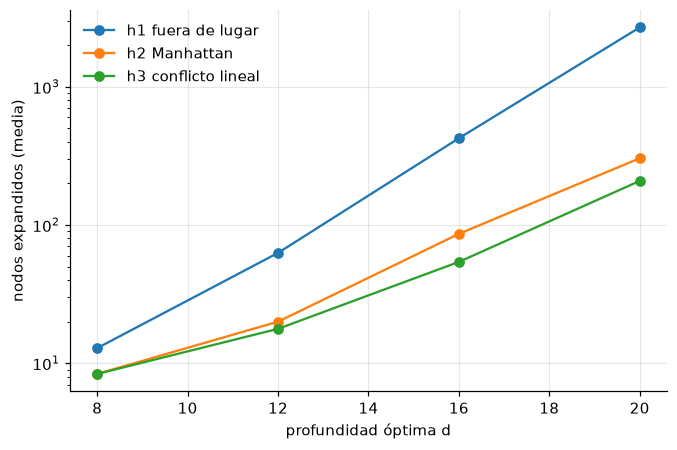

In [3]:
fig, ax = plt.subplots()
for name in H:
    pts = [(d, e) for d, n, e, _ in rows if n == name]
    ax.semilogy(*zip(*pts, strict=True), "o-", label=name)
ax.set_xlabel("profundidad óptima d")
ax.set_ylabel("nodos expandidos (media)")
ax.legend();

Cada mejora de la heurística reduce el exponente, no solo una constante: la diferencia crece
con la profundidad. Las tres son admisibles (los tests del módulo lo verifican sobre los 181 440
estados alcanzables) y forman una cadena de dominancia $h_1 \le h_2 \le h_3$.

## 2. A* vs. IDA*: memoria

A* guarda toda la frontera; IDA* solo el camino actual. En el 15-puzzle (10¹³ estados) A* agota
la memoria en instancias difíciles, mientras que IDA* con buena heurística las resuelve.

In [4]:
print(f"{'d':>3}{'A* exp.':>10}{'A* frontera':>13}{'IDA* exp.':>11}{'IDA* memoria':>14}")
for walk in [20, 30, 40]:
    s = random_state(4, np.random.default_rng(walk), walk=walk)
    p = SlidingPuzzle(s, 4)
    a, i = astar(p, linear_conflict(4)), ida_star(p, linear_conflict(4))
    assert a.cost == i.cost
    print(
        f"{int(a.cost):>3}{a.expanded:>10}{a.max_frontier:>13}{i.expanded:>11}{i.max_frontier:>14}"
    )

  d   A* exp.  A* frontera  IDA* exp.  IDA* memoria
  8         8           13          8             9


 30      3136         3132       6389            31


 38      4408         4008      16403            39


IDA* re-expande nodos en cada iteración (más tiempo) pero su memoria es la longitud del camino.
Es la elección estándar para puzzles con costos unitarios y heurísticas fuertes.

## Para llevar

- Inventar heurísticas = relajar restricciones del problema; el costo exacto del relajado es admisible.
- Comparar heurísticas por $b^*$ o por expansiones a profundidad fija, no en un solo ejemplo.
- El máximo de varias heurísticas admisibles es admisible y domina a cada una.